# 1.13. Эталоны, отступы и пограничный трафик

**Практикум для студентов информационной безопасности: пример SYN-flood.**

Мы выберем типичный образец каждого класса, обучим простой SVM и разберём, почему
рядом с границей решения нужен дополнительный анализ. В конце будет функция
предварительной сортировки трафика без автоматической блокировки.

**Данные синтетические.** Все 20 обучающих и 8 проверочных окон придуманы вручную.
Проверочные окна специально показывают разные ситуации, включая ошибки.
Они **не являются независимым бенчмарком качества**; результаты нельзя переносить
на реальную сеть или другие атаки.

**Как запустить в Google Colab:** «Среда выполнения» → «Выполнить все» (*Runtime → Run all*).
Данные встроены в ноутбук. Google Drive, загрузка файлов, GPU и ключи доступа не нужны.


## 1. Подготовим инструменты

NumPy нужен для расстояний, pandas — для таблиц, Matplotlib — для графика,
scikit-learn — для SVM. В стандартной среде Colab эти библиотеки обычно уже установлены.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from IPython.display import display

pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 160)
label_ru = {-1: "Нормальный трафик", 1: "SYN-flood"}
print("Инструменты готовы. Все данные находятся в ноутбуке.")


Инструменты готовы. Все данные находятся в ноутбуке.


## 2. Что наблюдаем в трафике

Один объект — **10-секундное окно на одном сервисе**. Используем два понятных признака:

- **SYN/с** — среднее число всех входящих SYN-пакетов в секунду за окно.
- **Без рукопожатия, %** — доля начатых в окне соединений, у которых полное TCP-рукопожатие
  не завершилось за фиксированные 3 секунды. При подсчёте попыток соединения повторные
  SYN дедуплицируются. Нужна видимость обоих направлений; результат готов после ожидания
  тайм-аута последней попытки в окне.

В учебной модели окна без SYN-попыток исключаем: при **SYN/с = 0** доля
незавершённых рукопожатий не определена. Для классификации нужна положительная
частота SYN/с. Это ограничение входных данных модели, а не признак атаки.

При SYN-flood сервер получает много запросов на соединение, часто без завершения
рукопожатия. Но потери сети и легитимный всплеск тоже могут ухудшить эти признаки.
Два числа не раскрывают намерение источника.

Метки заданы автором синтетического примера: **−1 — нормальный трафик, +1 — SYN-flood**.
Ниже 20 обучающих окон: по 10 каждого класса.


In [2]:
train_raw = pd.DataFrame([
    ['N01', 200, 5.0, -1], ['N02', 320, 8.0, -1],
    ['N03', 450, 10.0, -1], ['N04', 550, 8.0, -1],
    ['N05', 600, 15.0, -1], ['N06', 720, 12.0, -1],
    ['N07', 850, 18.0, -1], ['N08', 1050, 15.0, -1],
    ['N09', 920, 30.0, -1], ['N10', 750, 40.0, -1],
    ['A01', 1050, 65.0, 1], ['A02', 1200, 75.0, 1],
    ['A03', 1400, 82.0, 1], ['A04', 1600, 90.0, 1],
    ['A05', 1800, 92.0, 1], ['A06', 1300, 65.0, 1],
    ['A07', 1500, 75.0, 1], ['A08', 950, 60.0, 1],
    ['A09', 1100, 50.0, 1], ['A10', 800, 56.0, 1],
], columns=["ID", "SYN/с", "Без рукопожатия, %", "y"])
display(train_raw)


,ID,SYN/с,"Без рукопожатия, %",y
0,N01,200,5.0,-1
1,N02,320,8.0,-1
2,N03,450,10.0,-1
3,N04,550,8.0,-1
4,N05,600,15.0,-1
5,N06,720,12.0,-1
6,N07,850,18.0,-1
7,N08,1050,15.0,-1
8,N09,920,30.0,-1
9,N10,750,40.0,-1


Отдельные восемь окон **не участвуют в выборе эталонов и обучении SVM**.
Они подобраны для объяснения геометрии, включая пограничные ситуации.
Их метки нужны для разбора ошибок, а не для получения убедительного процента точности.
В первичном выводе покажем только наблюдаемые признаки; известные автору истинные
метки используем отдельно при оценке.


In [3]:
check_raw = pd.DataFrame([
    ['T01', 420, 9.0, -1], ['T02', 1550, 88.0, 1],
    ['T03', 950, 40.0, -1], ['T04', 900, 40.0, 1],
    ['T05', 1000, 42.0, -1], ['T06', 950, 46.0, 1],
    ['T07', 1200, 16.0, -1], ['T08', 950, 75.0, 1],
], columns=["ID", "SYN/с", "Без рукопожатия, %", "y"])
display(check_raw.drop(columns=["y"]))


,ID,SYN/с,"Без рукопожатия, %"
0,T01,420,9.0
1,T02,1550,88.0
2,T03,950,40.0
3,T04,900,40.0
4,T05,1000,42.0
5,T06,950,46.0
6,T07,1200,16.0
7,T08,950,75.0


## 3. Приведём признаки к фиксированному масштабу

Нельзя сравнивать расстояния, оставив сотни SYN/с рядом с долями единицы без обсуждения
масштаба: первый признак почти полностью определил бы расстояние.

Здесь заранее фиксируем: `x1 = SYN/с ÷ 1000`, `x2 = проценты ÷ 100`.
Например, 900 SYN/с и 40% становятся `(0.90, 0.40)`.
Масштаб не подбирается по проверочным окнам. Он учебный и влияет на расстояния.


In [4]:
feature_names = ["SYN/с", "Без рукопожатия, %"]
feature_scale = np.array([1000.0, 100.0])
X_train = train_raw[feature_names].to_numpy(dtype=float) / feature_scale
X_check = check_raw[feature_names].to_numpy(dtype=float) / feature_scale
y_train = train_raw["y"].to_numpy()
y_check = check_raw["y"].to_numpy()

example = pd.DataFrame(X_check, columns=["x1: SYN/с ÷ 1000", "x2: доля"])
display(pd.concat([check_raw[["ID"]], example], axis=1))


,ID,x1: SYN/с ÷ 1000,x2: доля
0,T01,0.42,0.09
1,T02,1.55,0.88
2,T03,0.95,0.40
3,T04,0.90,0.40
4,T05,1.00,0.42
5,T06,0.95,0.46
6,T07,1.20,0.16
7,T08,0.95,0.75


## 4. Найдём эталоны двух классов

**Эталон** здесь — типичный представитель своего класса из обучающих данных.
Выберем **медоид**: точку с наименьшей суммой расстояний до остальных точек своего класса.
Это существующий образец, а не среднее и не «идеальная норма».

Функция ниже перебирает кандидатов. При равенстве сумм выбирает меньший ID.
Расстояния евклидовы и считаются после показанного выше масштабирования.


In [5]:
def choose_medoid(points, ids):
    distances = np.linalg.norm(points[:, None, :] - points[None, :, :], axis=2)
    total_distances = distances.sum(axis=1)
    tied = np.flatnonzero(np.isclose(total_distances, total_distances.min(),
                                   rtol=0, atol=1e-12))
    best = min(tied, key=lambda i: ids[i])
    return ids[best], points[best].copy(), float(total_distances[best])

prototypes = {}
prototype_rows = []
for label in [-1, 1]:
    mask = y_train == label
    ident, point, total = choose_medoid(X_train[mask], train_raw.loc[mask, "ID"].to_numpy())
    prototypes[label] = point
    prototype_rows.append([label_ru[label], ident, point[0], point[1], total])
display(pd.DataFrame(prototype_rows, columns=["Класс", "Эталон", "x1", "x2", "Сумма расстояний"]).round(6))


,Класс,Эталон,x1,x2,Сумма расстояний
0,Нормальный трафик,N05,0.6,0.15,2.415511
1,SYN-flood,A06,1.3,0.65,2.882603


Получились **N05 = (0.60; 0.15)** и **A06 = (1.30; 0.65)**.
В исходных единицах это 600 SYN/с и 15%; 1300 SYN/с и 65%.

### Классификация по ближайшему эталону

Сравним расстояния до двух эталонов. Ближайший эталон задаёт прогноз.
**Эталонный отступ `Mref` — расстояние до чужого эталона минус расстояние до своего.**
«Свой» класс известен только потому, что в учебных данных задана истинная метка.

- `Mref > 0`: свой эталон ближе, ответ верен.
- `Mref < 0`: чужой эталон ближе, ответ ошибочен.
- `Mref = 0`: равенство расстояний; полезно отправить объект на проверку.

При точном равенстве наш технический выбор — «нормальный трафик», с отдельным флагом.


In [6]:
d_normal = np.linalg.norm(X_check - prototypes[-1], axis=1)
d_attack = np.linalg.norm(X_check - prototypes[1], axis=1)
score_difference = d_normal - d_attack
score_difference[np.isclose(score_difference, 0, rtol=0, atol=1e-12)] = 0
prototype_prediction = np.where(score_difference > 0, 1, -1)
Mref = y_check * score_difference
prototype_table = pd.DataFrame({"ID": check_raw["ID"],
    "До эталона нормы": d_normal, "До эталона атаки": d_attack,
    "Эталонный отступ Mref": Mref,
    "Прогноз по эталону": [label_ru[y] for y in prototype_prediction],
    "Равные расстояния": score_difference == 0})
display(prototype_table.round(4))


,ID,До эталона нормы,До эталона атаки,Эталонный отступ Mref,Прогноз по эталону,Равные расстояния
0,T01,0.1897,1.0431,0.8533,Нормальный трафик,False
1,T02,1.1981,0.3397,0.8584,SYN-flood,False
2,T03,0.4301,0.4301,-0.0000,Нормальный трафик,True
3,T04,0.3905,0.4717,-0.0812,Нормальный трафик,False
4,T05,0.4826,0.3780,-0.1046,SYN-flood,False
5,T06,0.4675,0.3982,0.0693,SYN-flood,False
6,T07,0.6001,0.5001,-0.1000,SYN-flood,False
7,T08,0.6946,0.3640,0.3306,SYN-flood,False


Посмотрите на **T01 и T02**: они близки к эталону своего класса.
У **T04** истинный класс — атака, но эталон нормы ближе: простой классификатор ошибается.
**T03** равноудалён от обоих эталонов. Объект **T07** тоже будет полезен:
эталонный классификатор относит его к атаке, хотя истинная метка — норма.

Один эталон описывает класс грубо. Теперь используем расположение всех обучающих точек.


## 5. Обучим линейный SVM с мягким зазором

SVM проводит границу между классами и стремится оставить вокруг неё свободную полосу.
**Мягкий зазор** допускает точки внутри этой полосы и даже ошибки, штрафуя их.
Параметр `C` регулирует силу штрафа. Фиксируем **C = 1**, не подбирая его по нашим
иллюстративным проверочным точкам.

Вызов `fit` использует только обучающие окна. Полученная функция `f` меняет знак
на границе: отрицательный знак даёт норму, положительный — атаку.


In [7]:
svm = SVC(kernel="linear", C=1.0, tol=1e-10, shrinking=False)
svm.fit(X_train, y_train)
w = svm.coef_[0]
b = float(svm.intercept_[0])
norm_w = float(np.linalg.norm(w))
prediction = svm.predict(X_check)
f = svm.decision_function(X_check)
m = y_check * f
gamma = m / norm_w
d = np.abs(f) / norm_w
TAU = 0.10
needs_review = d < TAU
print(f"w = {w.round(6)}, b = {b:.6f}, ‖w‖ = {norm_w:.6f}")
print(f"Опорных обучающих объектов: {len(svm.support_)}")


w = [1.216667 2.116667], b = -2.047500, ‖w‖ = 2.441425
Опорных обучающих объектов: 12


## 6. Как читать результат без сложных формул

**Расстояние `d` до границы** показывает, насколько мало нужно изменить два
масштабированных признака, чтобы дойти до смены решения.
Если `d` мало, решение пограничное. Для демонстрации поставим в очередь проверки
окна с **d < 0.10**. Это учебный порог, а не проверенное правило для реальной сети.

**Подозрение на атаку и пограничность — два разных сигнала.** Прогноз «SYN-flood»
создаёт предварительный алерт даже далеко от границы. Малое расстояние добавляет
пограничную проверку и для нормы, и для атаки. Очередь по `d` не является ранжированием
общего риска инцидента и не заменяет очередь алертов.

**Размеченный отступ `gamma`** добавляет к расстоянию знак правильности:
плюс — верный ответ, минус — ошибка. Его можно посчитать после получения истинной метки.
В работе без метки доступно `d`, но неизвестно, правильный ли прогноз.


In [8]:
def suggested_action(attack, review):
    if attack:
        return "Алерт + пограничная проверка" if review else "Алерт по подозрению на атаку"
    return "Дополнительная проверка" if review else "Наблюдение"

suspected_attack = prediction == 1
check_table = pd.DataFrame({
    "ID": check_raw["ID"],
    "Прогноз SVM": [label_ru[y] for y in prediction],
    "Расстояние до границы d": d,
    "Предварительный алерт": np.where(suspected_attack, "Да", "Нет"),
    "Пограничная проверка": np.where(needs_review, "Да", "Нет"),
    "Предлагаемое действие": [suggested_action(a, r) for a, r in zip(suspected_attack, needs_review)]
})
display(check_table.round(4))
print("Пограничная очередь:", ", ".join(check_raw.loc[needs_review, "ID"]))


,ID,Прогноз SVM,Расстояние до границы d,Предварительный алерт,Пограничная проверка,Предлагаемое действие
0,T01,Нормальный трафик,0.5513,Нет,Нет,Наблюдение
1,T02,SYN-flood,0.6967,Да,Нет,Алерт по подозрению на атаку
2,T03,Нормальный трафик,0.0184,Нет,Да,Дополнительная проверка
3,T04,Нормальный трафик,0.0433,Нет,Да,Дополнительная проверка
4,T05,SYN-flood,0.0238,Да,Да,Алерт + пограничная проверка
5,T06,SYN-flood,0.0336,Да,Да,Алерт + пограничная проверка
6,T07,Нормальный трафик,0.1019,Нет,Нет,Наблюдение
7,T08,SYN-flood,0.2850,Да,Нет,Алерт по подозрению на атаку


Пограничная очередь: T03, T04, T05, T06


**T02** даёт алерт при большом `d ≈ 0.6967` и не входит в пограничную очередь.
Только `d < 0.10` не могло бы служить правилом обнаружения атаки.

### Отдельно оценим ответы, открыв известные автору метки

Теперь используем истинные метки для двух показательных ошибок.
Модель и функция предварительной сортировки этих меток не видят.


In [9]:
evaluation = pd.DataFrame({"ID": check_raw["ID"],
    "Истинный класс": [label_ru[y] for y in y_check],
    "Прогноз SVM": [label_ru[y] for y in prediction],
    "Разбор ошибки": ["Верно" if real == pred else "Пропуск атаки" if real == 1 else "Ложная тревога"
                      for real, pred in zip(y_check, prediction)]})
display(evaluation.loc[evaluation["ID"].isin(["T04", "T05"])])


,ID,Истинный класс,Прогноз SVM,Разбор ошибки
3,T04,SYN-flood,Нормальный трафик,Пропуск атаки
4,T05,Нормальный трафик,SYN-flood,Ложная тревога


### Что заметит аналитик ИБ

- **T04 — пропуск атаки:** истинная атака принята за норму; `d ≈ 0.0433`.
- **T05 — ложная тревога:** нормальная нагрузка принята за атаку; `d ≈ 0.0238`.
- **T03 и T06** классифицированы верно, но тоже находятся рядом с границей.
- **T07:** SVM верно распознал норму, хотя ближайший эталон дал атаку.
  Его `d ≈ 0.1019` едва больше учебного порога: число 0.10 не создаёт гарантии.

**Очередь проверки помогает заметить обе показанные ошибки, но не гарантирует
обнаружение любых ошибок.** Большое расстояние означает устойчивость текущего прогноза
к небольшому изменению этих признаков. Даже устойчивый прогноз может быть неверным.


## 7. Увидим границу и зону проверки

Синие точки — норма, красные — SYN-flood. Круги и квадраты — обучение;
ромбы — восемь иллюстративных проверок. Чёрная линия — граница SVM,
серая полоса — окна с `d < 0.10`.

На осях показаны исходные единицы, удобные для анализа трафика.
Само расстояние `d` считается в масштабированных координатах из шага 3.
Сначала подготовим сетку возможных сочетаний двух признаков.


In [10]:
grid_syn, grid_percent = np.meshgrid(np.linspace(100, 1900, 400),
                                   np.linspace(0, 100, 300))
grid_features = np.column_stack([grid_syn.ravel(), grid_percent.ravel()]) / feature_scale
grid_f = svm.decision_function(grid_features).reshape(grid_syn.shape)
grid_distance = np.abs(grid_f) / norm_w


Теперь нанесём обучающие и проверочные окна. Подпишем две ошибки из таблицы.
Серая полоса означает необходимость разбора, а не обнаруженную атаку.


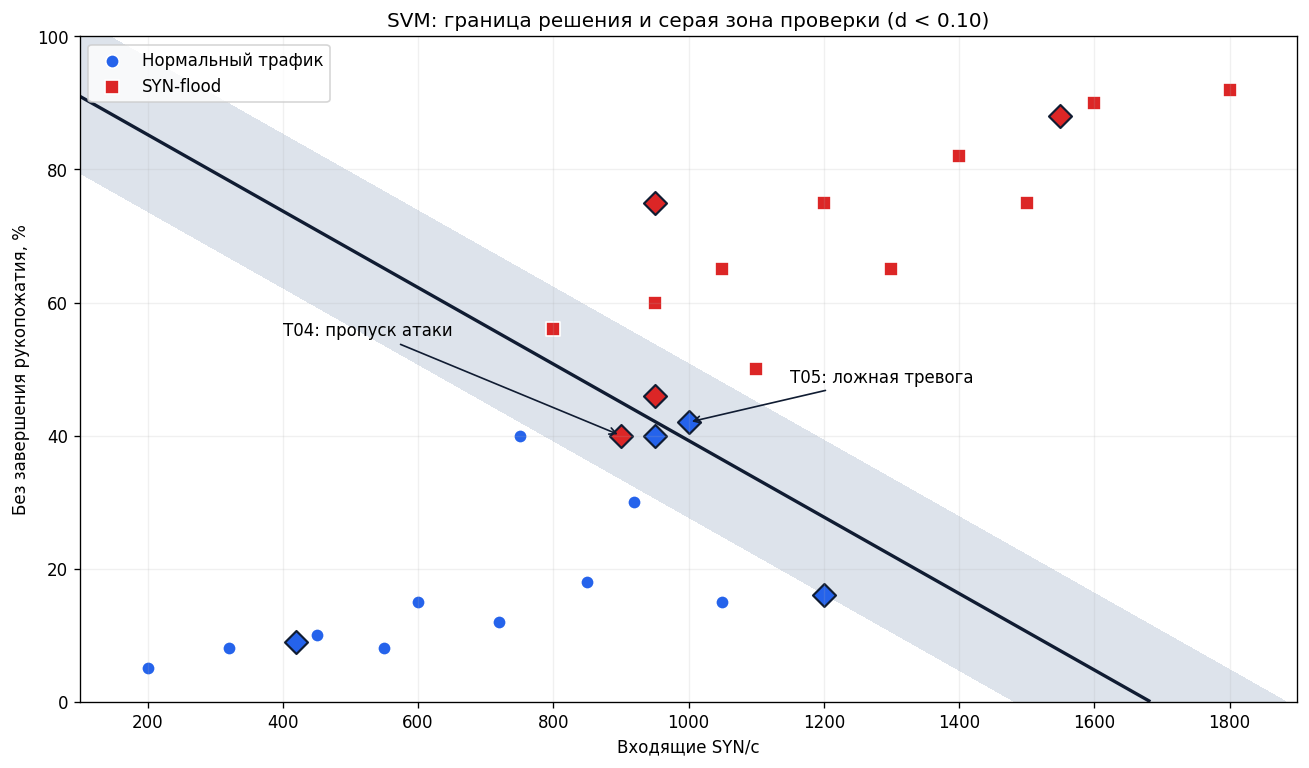

In [11]:
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.contourf(grid_syn, grid_percent, grid_distance, levels=[0, TAU], colors=["#CBD5E1"], alpha=0.65)
ax.contour(grid_syn, grid_percent, grid_f, levels=[0], colors=["#101C32"], linewidths=2)
for label, marker, color in [(-1, "o", "#2563EB"), (1, "s", "#DC2626")]:
    mask = y_train == label
    ax.scatter(train_raw.loc[mask, "SYN/с"], train_raw.loc[mask, "Без рукопожатия, %"],
               marker=marker, c=color, s=65, edgecolor="white", label=label_ru[label])
for label, color in [(-1, "#2563EB"), (1, "#DC2626")]:
    mask = y_check == label
    ax.scatter(check_raw.loc[mask, "SYN/с"], check_raw.loc[mask, "Без рукопожатия, %"],
               marker="D", c=color, s=95, edgecolor="#101C32", linewidth=1.3)
for ident, text, xytext in [("T04", "T04: пропуск атаки", (400, 55)),
                          ("T05", "T05: ложная тревога", (1150, 48))]:
    row = check_raw.loc[check_raw["ID"] == ident].iloc[0]
    ax.annotate(text, (row["SYN/с"], row["Без рукопожатия, %"]), xytext=xytext,
                arrowprops={"arrowstyle": "->", "color": "#101C32"}, fontsize=10)
ax.set(xlim=(100, 1900), ylim=(0, 100), xlabel="Входящие SYN/с", ylabel="Без завершения рукопожатия, %",
       title="SVM: граница решения и серая зона проверки (d < 0.10)")
ax.grid(alpha=0.18)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()


## 8. Функция предварительной сортировки нового окна

`triage` принимает **исходные единицы**: SYN/с и проценты. Она применяет тот же
масштаб и возвращает предварительный класс, флаг подозрения/алерта,
отдельный флаг пограничной проверки, расстояние и предлагаемое действие.
Истинная метка ей неизвестна. Функция **не блокирует соединения и не настраивает сеть**.
Нулевая или отрицательная частота SYN/с не допускается: пустые окна исключаются,
поскольку для них доля незавершённых рукопожатий не определена.

`suspected_attack` и `attack_alert` в этом примере совпадают: оба истинны при прогнозе атаки.
`boundary_review` отвечает только за близость к границе. Алерт может возникнуть
при любом расстоянии; пограничная проверка может дополнять алерт.


In [12]:
def triage(syn_per_second, unfinished_percent):
    values = np.array([syn_per_second, unfinished_percent], dtype=float)
    if not np.isfinite(values).all():
        raise ValueError("Нужны конечные числовые значения.")
    if values[0] <= 0:
        raise ValueError("Для классификации нужен положительный SYN/с; окна без попыток исключаем")
    if not 0 <= values[1] <= 100:
        raise ValueError("Доля незавершённых рукопожатий должна быть от 0 до 100%.")
    features = values.reshape(1, -1) / feature_scale
    predicted_label = int(svm.predict(features)[0])
    distance = abs(float(svm.decision_function(features)[0])) / norm_w
    attack, review = predicted_label == 1, bool(distance < TAU)
    return {"predicted_class": label_ru[predicted_label], "suspected_attack": attack,
            "attack_alert": attack, "boundary_review": review,
            "distance": round(distance, 6), "action": suggested_action(attack, review)}


Пять примеров ниже воспроизводят разные ситуации. Обратите внимание: функция
отправляет пограничные окна на проверку и отдельно формирует алерт при прогнозе
атаки. Без истинной метки она не может назвать прогноз ошибочным.
В таблице нет истинных меток или описаний реального сценария; это вход и выход модели.
Измените входные числа и повторно выполните ячейку.


In [13]:
demo_inputs = [(420, 9), (1550, 88), (950, 40), (900, 40), (1000, 42)]
demo_rows = []
for syn, percent in demo_inputs:
    demo_rows.append({"SYN/с": syn, "Без рукопожатия, %": percent,
                      **triage(syn, percent)})
display(pd.DataFrame(demo_rows))


,SYN/с,"Без рукопожатия, %",predicted_class,suspected_attack,attack_alert,boundary_review,distance,action
0,420,9,Нормальный трафик,False,False,False,0.551317,Наблюдение
1,1550,88,SYN-flood,True,True,False,0.696724,Алерт по подозрению на атаку
2,950,40,Нормальный трафик,False,False,True,0.018432,Дополнительная проверка
3,900,40,Нормальный трафик,False,False,True,0.043349,Дополнительная проверка
4,1000,42,SYN-flood,True,True,True,0.023825,Алерт + пограничная проверка


## 9. Короткие задания для самостоятельного разбора

1. Найдите в таблицах случай, где ближайший эталон и SVM дали разные ответы.
   Какой ответ совпал с известной меткой?
2. Почему нормальный трафик с потерями может напоминать SYN-flood по этим признакам?
3. Измените вход функции с `(950, 40)` на `(950, 43)`. Изменился ли класс?
   Увеличивает ли это уверенность в реальном наличии атаки?
4. Если уменьшить `TAU`, как изменится очередь проверки? Почему меньшая очередь
   не обязательно означает лучший детектор?

Ожидаемая идея: близость к границе характеризует чувствительность решения,
а истинная метка нужна для оценки его правильности.

## 10. Что нужно для реальной эксплуатации

Этот ноутбук не доказывает эффективность детектора. Для практической системы нужны
реальные размеченные данные конкретной инфраструктуры, независимая проверка
на более поздних периодах, анализ пропусков и ложных тревог, проверка дисбаланса классов,
подбор масштаба и параметров на отдельной валидации. Нужны также корректная видимость
рукопожатий, учёт повторов и потерь, дополнительные признаки и наблюдение за изменением
поведения сети. Порог очереди выбирают с учётом стоимости ошибок и возможностей аналитиков.

Решение о защитном действии требует отдельной политики и проверки. Здесь реализована
только учебная предварительная сортировка.


## Дополнение: подробные числа и определения

Этот раздел можно пропустить при первом прохождении.

| Обозначение | Смысл |
|---|---|
| `f = w₁x₁ + w₂x₂ + b` | Знак задаёт класс; ноль — граница |
| `m = y·f` | Функциональный размеченный отступ |
| `gamma = y·f / ‖w‖` | Геометрический размеченный отступ: плюс — верно, минус — ошибка |
| `d = abs(f) / ‖w‖` | Расстояние до гиперплоскости в масштабированных координатах |
| `max(0, 1−m)` | Hinge loss: штраф за недостаточный отступ |
| `Mref = d_чужой − d_свой` | Эталонный отступ, не равный расстоянию до границы SVM |

У обучающих объектов минимальная slack-переменная мягкого зазора равна
`max(0, 1−m)`. Для проверочных объектов ниже это **hinge loss для анализа**,
а не переменная уже решённой задачи обучения.
Только обучающие точки могут быть опорными векторами; пограничная проверочная
точка автоматически опорным вектором не становится.


In [14]:
detail_table = pd.DataFrame({"ID": check_raw["ID"], "y": y_check,
    "f": f, "m = y*f": m, "gamma = y*f/‖w‖": gamma,
    "d = |f|/‖w‖": d, "hinge = max(0,1-m)": np.maximum(0, 1 - m),
    "Mref": Mref})
display(detail_table.round(6))
train_m = y_train * svm.decision_function(X_train)
print("Опорные обучающие ID:", ", ".join(train_raw.iloc[svm.support_]["ID"]))
print("Обучающих объектов внутри единичного отступа:", int(np.sum(train_m < 1 - 1e-6)))
print(f"Ширина номинальной полосы мягкого зазора: 2/‖w‖ = {2/norm_w:.6f}")


,ID,y,f,m = y*f,gamma = y*f/‖w‖,d = |f|/‖w‖,"hinge = max(0,1-m)",Mref
0,T01,-1,-1.346000,1.346000,0.551317,0.551317,0.000000,0.853336
1,T02,1,1.701000,1.701000,0.696724,0.696724,0.000000,0.858376
2,T03,-1,-0.045000,0.045000,0.018432,0.018432,0.955000,-0.000000
3,T04,1,-0.105833,-0.105833,-0.043349,0.043349,1.105833,-0.081187
4,T05,-1,0.058167,-0.058167,-0.023825,0.023825,1.058167,-0.104576
5,T06,1,0.082000,0.082000,0.033587,0.033587,0.918000,0.069301
6,T07,-1,-0.248833,0.248833,0.101921,0.101921,0.751167,-0.099983
7,T08,1,0.695833,0.695833,0.285011,0.285011,0.304167,0.330617


Опорные обучающие ID: N05, N06, N07, N08, N09, N10, A01, A02, A06, A08, A09, A10
Обучающих объектов внутри единичного отступа: 10
Ширина номинальной полосы мягкого зазора: 2/‖w‖ = 0.819194


### Ручная проверка T04

Для `x = (0.90; 0.40)` истинная метка — `+1`:

- `f ≈ 1.216667·0.90 + 2.116667·0.40 − 2.047500 = −0.105833`.
- `m ≈ −0.105833`, `gamma ≈ −0.043349`, `d ≈ 0.043349`.
- До эталона нормы `≈ 0.390512`; до эталона атаки `≈ 0.471699`.
- `Mref ≈ −0.081187`: чужой эталон ближе.

Обе модели ошибаются на этой точке; она находится в зоне проверки SVM.

**Границы интерпретации:** `d` — минимальная длина произвольного изменения вектора
признаков до гиперплоскости. Это не вероятность атаки, не гарантия правильности
и не оценка физически достижимого изменения исходного трафика.

### Источники для продолжения

- [Документация scikit-learn: SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html)
- [Руководство scikit-learn: support vector machines](https://scikit-learn.org/stable/modules/svm.html)
- [RFC 4987: TCP SYN Flooding Attacks and Common Mitigations](https://www.rfc-editor.org/rfc/rfc4987)

Источники объясняют метод и контекст атаки. Числа этого ноутбука — авторский
синтетический пример, а не данные из RFC или документации scikit-learn.


### Необязательное математическое дополнение: мягкий зазор

$$\min_{w,b,\xi}\; \frac{1}{2}\lVert w\rVert^2 + C\sum_i\xi_i.$$

$$y_i(w^\mathsf{T}x_i+b)\ge 1-\xi_i,\qquad \xi_i\ge 0.$$

`C` задаёт цену нарушения отступа: чем больше `C`, тем сильнее штраф за такие нарушения.
